In [92]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import BernoulliNB

Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

CATEGORICAL = ["carrier", "origin", "dest", "month", "day_of_week", "dep_hour", "arr_hour"]
NUMERIC = ["distance"]

df = pd.read_parquet("data/processed/flights.parquet")
for col in ["carrier", "origin", "dest"]:
    df[col] = df[col].astype(str)

In [93]:
# Random samples
train = df[df["year"] == 2025].sample(400_000, random_state=42)
test = df[df["year"] == 2026].sample(100_000, random_state=42)
# train = df[df["year"] == 2025].sample(100_000, random_state=42)
# test = df[df["year"] == 2026].sample(10_000, random_state=42)
train, val = train_test_split(train, test_size=0.1, random_state=42)

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=200), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])
X_train = prep.fit_transform(train)
X_val = prep.transform(val)
X_test = prep.transform(test)

y_train = train["late"]
y_test = test["late"]
y_val = val["late"]

In [94]:
class BetaBinomial:
    def fit(self, train):
        self.mean = train["late"].mean()

        alpha = self.mean
        beta = (1 - self.mean)

        results = (
            train.groupby(["carrier", "origin"], observed=True)["late"]
            .agg(flights="count", late="sum")
            .reset_index()
        )

        n, y = results["flights"], results["late"]

        a_star = alpha + y
        b_star = beta + n - y

        # posterior mean
        results["estimated_rate"] = a_star / (a_star + b_star)
        self.results = results
        return results

    def predict(self, data):
        out = data.merge(
            self.results[["carrier", "origin", "estimated_rate"]],
            on=["carrier", "origin"], how="left",
        )
        return out["estimated_rate"].fillna(self.mean).to_numpy()

In [95]:
model = BetaBinomial()
model.fit(train)
model.results

,carrier,origin,flights,late,estimated_rate
0,AA,ABQ,156,21,0.135181
1,AA,AGS,3,0,0.055870
2,AA,ALB,63,13,0.206617
3,AA,AMA,4,2,0.444696
4,AA,ANC,24,12,0.488939
...,...,...,...,...,...
1608,YX,TUL,51,9,0.177375
1609,YX,TVC,22,8,0.357543
1610,YX,TYS,52,10,0.192896
1611,YX,VPS,2,2,0.741160


In [96]:
y_pred = model.predict(test)
y_pred

array([0.2239523 , 0.36548331, 0.21928777, ..., 0.15143429, 0.22223757,
       0.25232388], shape=(100000,))

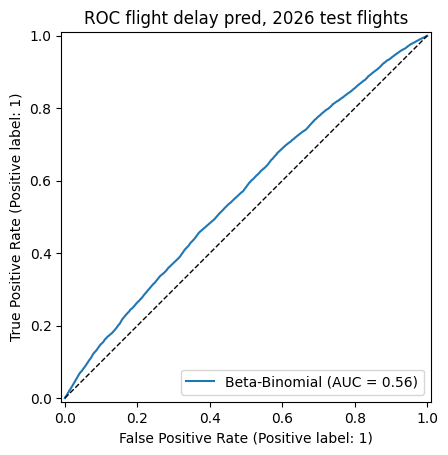

In [97]:
RocCurveDisplay.from_predictions(y_test, y_pred, name="Beta-Binomial")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.title("ROC flight delay pred, 2026 test flights")
plt.show()

In [98]:
model.results.sort_values("estimated_rate", ascending=False).head(20)

,carrier,origin,flights,late,estimated_rate
1319,UA,ECP,5,5,0.870580
291,B6,VRB,3,3,0.805870
21,AA,CAE,3,3,0.805870
1551,YX,FSD,2,2,0.741160
1611,YX,VPS,2,2,0.741160
922,OH,AUS,2,2,0.741160
243,B6,HDN,2,2,0.741160
652,G4,TRI,9,7,0.722348
651,G4,TOL,23,16,0.675978
1097,OO,DHN,4,3,0.644696
